# 02 · Fall detection experiments

**Goal:** measure how well SentryCare detects falls and avoids false alarms, compare the **previous** pipeline
(MediaPipe, one person) with the **current** pipeline (YOLO11-pose, many people), and test the design choices.

**Dataset:** [UR Fall Detection Dataset (URFD)](https://fenix.ur.edu.pl/~mkepski/ds/uf.html): short videos of
staged falls and of normal activities (walking, sitting, crouching, lying on a bed), with frame-by-frame labels of
when each fall happens. Licence CC BY-NC-SA 4.0 (non-commercial academic use).

**Before running:** download the clips (about 1 GB) from the repository root:
```
python scripts/download_urfd_samples.py --falls 15 --adls 15
```

**Key terms**
| Term | Meaning |
|---|---|
| Fall clip / ADL clip | A video with a real fall / a video of normal daily activity (no fall) |
| Detected fall (TP) | A fall clip where the system raised an alert |
| Missed fall (FN) | A fall clip with no alert |
| False alarm (FP) | An alert on a normal-activity clip |
| Recall | Share of falls detected = TP / (TP + FN) |
| Alert delay | Seconds from the moment the fall starts (dataset label) to the alert |

In [1]:
# --- Setup -------------------------------------------------------------------------------------
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import fall_experiments as fx                       # helper functions in this folder
from sentrycare.body_tracking import TrackerSettings
from sentrycare.sources import annotate

ROOT = Path("..")
MANIFEST = ROOT / "data/evaluation/urfd_extended.csv"
LABELS = ROOT / "data/datasets/urfd_samples/urfall-cam0-falls.csv"
CACHE = ROOT / "data/evaluation/pose_cache_urfd.json"
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
FIGURES = ROOT / "report/figures"; FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
assert MANIFEST.is_file(), "Run: python scripts/download_urfd_samples.py --falls 15 --adls 15"
print(f"Analysis rate: {1 / fx.CADENCE:.0f} frames per second (same as the live system)")

Analysis rate: 5 frames per second (same as the live system)


## 1. Dataset

Clips 01–02 of each type were used while developing the method, so they are marked **dev**. Results are reported
on the remaining **test** clips (03–15) and on all clips.

URFD videos stop about 1–2 seconds after the fall. Our system waits for the person to *stay down* before alerting, so
we report two views:
- **raw:** the video exactly as recorded.
- **held:** the last frame is repeated for 4 seconds, as if the person stayed where they are. This is applied to
  **both** fall and normal clips, so the test stays fair.

In [2]:
clips = fx.load_manifest(MANIFEST)
onsets = fx.load_fall_onsets(LABELS, clips)        # when each fall starts, from the dataset's own labels
overview = pd.DataFrame([{"clip": c["clip"], "type": c["label"], "split": c["split"]} for c in clips])
overview.groupby(["type", "split"]).size().unstack(fill_value=0)

split,dev,test
type,,
adl,2,13
fall,2,13


## 2. Run the pose models once

Each clip is processed by both models at 5 frames per second. The raw outputs (body boxes and keypoints) are
cached, so the experiments below only re-run the fall *logic*, which takes seconds. The first run takes about 3 minutes on a laptop CPU.

In [3]:
cache = fx.build_cache(clips, CACHE)
speed = pd.DataFrame({
    "model": ["YOLO11n-pose + ByteTrack (current)", "MediaPipe Pose (previous)"],
    "median ms / frame": [np.median([m for r in cache.values() for m in r["yolo_ms"]]),
                          np.median([m for r in cache.values() for m in r["mediapipe_ms"]])],
}).round(1)
speed["max frames / s"] = (1000 / speed["median ms / frame"]).round(1)
speed

,model,median ms / frame,max frames / s
0,YOLO11n-pose + ByteTrack (current),101.8,9.8
1,MediaPipe Pose (previous),42.3,23.6


## 3. What the system sees
Four moments from one fall clip, with the boxes, skeletons and states drawn by the live system's own drawing code.

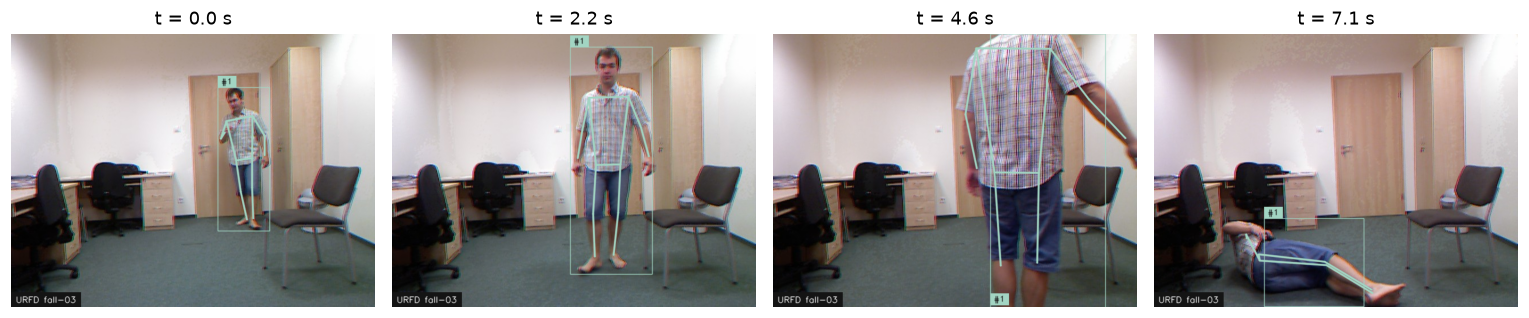

In [4]:
from sentrycare.body_tracking import MultiPersonFallMonitor
clip = next(c for c in clips if c["clip"] == "fall-03")
record = cache["fall-03"]
monitor = MultiPersonFallMonitor(1.2, model=object())
frames = list(fx.sampled_frames(clip))
annotated = []
for (frame, t), dets in zip(frames, record["yolo"]):
    people = monitor.update(frame, t, detections=[(i, b, np.array(k), None if c is None else np.array(c), s)
                                                   for i, b, k, c, s in dets])
    result = {"faces": [], "people": people, "fall": {}, "width": frame.shape[1], "height": frame.shape[0]}
    annotated.append(annotate(frame, result, "URFD fall-03"))

picks = np.linspace(0, len(annotated) - 1, 4).astype(int)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, i in zip(axes, picks):
    ax.imshow(cv2.cvtColor(annotated[i], cv2.COLOR_BGR2RGB)); ax.set_title(f"t = {frames[i][1]:.1f} s"); ax.axis("off")
fig.tight_layout(); fig.savefig(FIGURES / "fall_sequence.png", dpi=150); plt.show()

## 4. Experiment 1: previous vs current pipeline

For every clip we check whether an alert was raised (and when), using the default settings of each pipeline.

In [5]:
rows = []
for c in clips:
    r = cache[c["clip"]]
    row = {"clip": c["clip"], "label": c["label"], "split": c["split"]}
    row["mediapipe_raw"] = fx.replay_mediapipe(r, hold=0)
    row["mediapipe_held"] = fx.replay_mediapipe(r)
    row["yolo_raw"] = fx.replay_yolo(r, hold=0)[0]
    row["yolo_held"] = fx.replay_yolo(r)[0]
    row["max_people"] = max(len(f) for f in r["yolo"])
    rows.append(row)
per_clip = pd.DataFrame(rows)

table = []
for name, key in [("Previous (MediaPipe)", "mediapipe"), ("Current (YOLO11-pose)", "yolo")]:
    for view in ("raw", "held"):
        for subset, data in (("test", [r for r in rows if r["split"] == "test"]), ("all", rows)):
            table.append({"pipeline": name, "view": view, "clips": subset,
                          **fx.classification_metrics(data, f"{key}_{view}")})
comparison = pd.DataFrame(table)
comparison.to_csv(RESULTS / "fall_pipeline_comparison.csv", index=False)
per_clip.to_csv(RESULTS / "fall_per_clip.csv", index=False)
comparison

,pipeline,view,clips,TP,FN,FP,TN,recall,precision,f1,specificity,accuracy
0,Previous (MediaPipe),raw,test,3,10,0,13,0.231,1.000,0.375,1.000,0.615
1,Previous (MediaPipe),raw,all,4,11,0,15,0.267,1.000,0.421,1.000,0.633
2,Previous (MediaPipe),held,test,7,6,1,12,0.538,0.875,0.666,0.923,0.731
3,Previous (MediaPipe),held,all,8,7,1,14,0.533,0.889,0.666,0.933,0.733
4,Current (YOLO11-pose),raw,test,0,13,0,13,0.000,NaN,0.000,1.000,0.500
5,Current (YOLO11-pose),raw,all,0,15,0,15,0.000,NaN,0.000,1.000,0.500
6,Current (YOLO11-pose),held,test,9,4,0,13,0.692,1.000,0.818,1.000,0.846
7,Current (YOLO11-pose),held,all,11,4,0,15,0.733,1.000,0.846,1.000,0.867


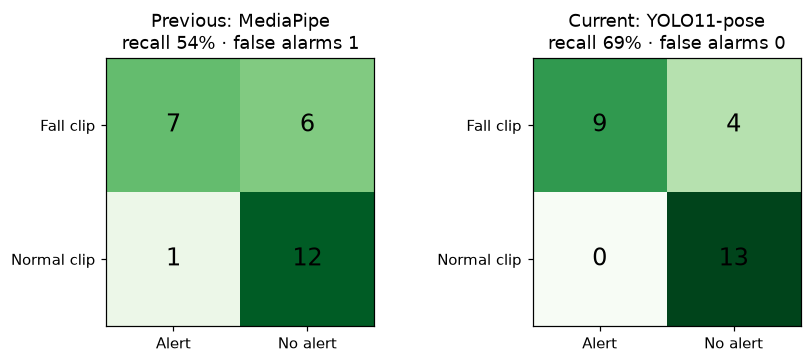

In [6]:
# Confusion matrices for the main result: held view, test clips.
test = [r for r in rows if r["split"] == "test"]
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, (title, key) in zip(axes, [("Previous: MediaPipe", "mediapipe_held"), ("Current: YOLO11-pose", "yolo_held")]):
    m = fx.classification_metrics(test, key)
    grid = np.array([[m["TP"], m["FN"]], [m["FP"], m["TN"]]])
    ax.imshow(grid, cmap="Greens", vmin=0, vmax=13)
    for (i, j), v in np.ndenumerate(grid):
        ax.text(j, i, v, ha="center", va="center", fontsize=16, color="black")
    ax.set_xticks([0, 1], ["Alert", "No alert"]); ax.set_yticks([0, 1], ["Fall clip", "Normal clip"])
    ax.set_title(f"{title}\nrecall {m['recall']:.0%} · false alarms {m['FP']}"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIGURES / "fall_confusion.png", dpi=200); plt.show()

## 5. Alert delay

Using the dataset's labels, we measure how many seconds pass between the **start of the fall** and the **alert**,
for each detected fall (held view).

In [7]:
delay = []
for r in rows:
    if r["label"] != "fall" or r["clip"] not in onsets:
        continue
    for name, key in [("Previous (MediaPipe)", "mediapipe_held"), ("Current (YOLO11-pose)", "yolo_held")]:
        if r[key] is not None:
            delay.append({"pipeline": name, "clip": r["clip"], "delay_s": round(r[key] - onsets[r["clip"]], 2)})
delay = pd.DataFrame(delay)
delay_summary = delay.groupby("pipeline").delay_s.describe()[["count", "min", "50%", "max"]].rename(columns={"50%": "median"})
delay_summary.round(2)

,count,min,median,max
pipeline,,,,
Current (YOLO11-pose),11.0,3.7,4.44,5.67
Previous (MediaPipe),8.0,1.9,2.60,3.50


## 6. Experiment 2: how long must the person stay down?

The **stayed-down check** waits for the person to remain low and still before alerting. It is meant to stop
alarms when someone drops quickly but gets straight back up (e.g. sitting down hard, kneeling to pick something up).
A longer wait is safer against such alarms but delays the alert. We try several durations and look at both effects.

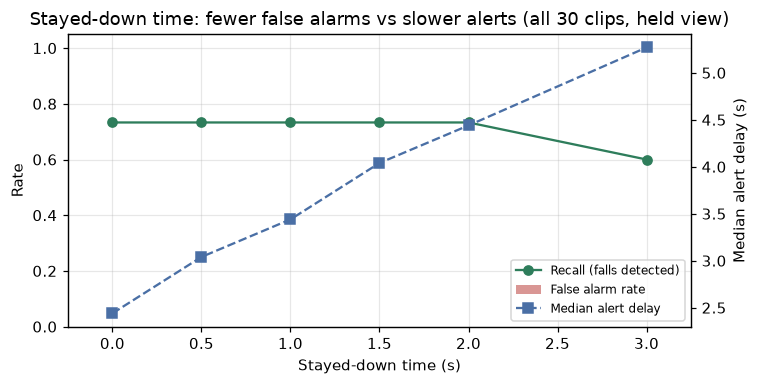

,stay_down_s,falls_detected,recall,false_alarms,median_delay_s
0,0.0,11/15,0.733,0,2.44
1,0.5,11/15,0.733,0,3.04
2,1.0,11/15,0.733,0,3.44
3,1.5,11/15,0.733,0,4.04
4,2.0,11/15,0.733,0,4.44
5,3.0,9/15,0.600,0,5.27


In [8]:
sweep = []
for stay in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]:
    settings = TrackerSettings(stay_down_seconds=stay)
    out = []
    for c in clips:
        alert = fx.replay_yolo(cache[c["clip"]], settings=settings)[0]
        out.append({"label": c["label"], "split": c["split"], "alert": alert,
                    "delay": alert - onsets[c["clip"]] if alert is not None and c["clip"] in onsets else None})
    m = fx.classification_metrics(out, "alert")
    delays = [o["delay"] for o in out if o["delay"] is not None]
    sweep.append({"stay_down_s": stay, "falls_detected": f"{m['TP']}/{m['TP'] + m['FN']}", "recall": m["recall"],
                  "false_alarms": m["FP"], "median_delay_s": round(float(np.median(delays)), 2) if delays else None})
sweep = pd.DataFrame(sweep)
sweep.to_csv(RESULTS / "stay_down_sweep.csv", index=False)

fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.plot(sweep.stay_down_s, sweep.recall, "o-", color="#2e7d5b", label="Recall (falls detected)")
ax1.bar(sweep.stay_down_s, sweep.false_alarms / 15, width=.18, color="#c0504d", alpha=.6, label="False alarm rate")
ax1.set_xlabel("Stayed-down time (s)"); ax1.set_ylabel("Rate"); ax1.set_ylim(0, 1.05)
ax2 = ax1.twinx(); ax2.plot(sweep.stay_down_s, sweep.median_delay_s, "s--", color="#4a6fa5", label="Median alert delay")
ax2.set_ylabel("Median alert delay (s)"); ax2.grid(False)
lines = ax1.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
ax1.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="lower right", fontsize=8)
ax1.set_title("Stayed-down time: fewer false alarms vs slower alerts (all 30 clips, held view)")
fig.tight_layout(); fig.savefig(FIGURES / "stay_down_sweep.png", dpi=200); plt.show()
sweep

## 7. Experiment 3: what does each part contribute? (ablation)

We switch off one component at a time and re-measure (all 30 clips, held view):
- **Stayed-down check:** wait 0 s instead of 2 s.
- **Box continuation:** when body points are lost, do not use the lying body box.
- **Track hand-off:** a person given a new ID by the tracker does not inherit the fall history.

In [9]:
variants = {
    "Full system": TrackerSettings(),
    "Without stayed-down check": TrackerSettings(stay_down_seconds=0.0),
    "Without box continuation": TrackerSettings(lying_aspect=1e9),
    "Without track hand-off": TrackerSettings(handoff_distance=0.0),
}
ablation = []
for name, settings in variants.items():
    out = [{"label": c["label"], "alert": fx.replay_yolo(cache[c["clip"]], settings=settings)[0]} for c in clips]
    m = fx.classification_metrics(out, "alert")
    ablation.append({"variant": name, "falls_detected": f"{m['TP']}/15", "false_alarms": f"{m['FP']}/15",
                     "recall": m["recall"], "precision": m["precision"], "f1": m["f1"]})
ablation = pd.DataFrame(ablation)
ablation.to_csv(RESULTS / "ablation.csv", index=False)
ablation

,variant,falls_detected,false_alarms,recall,precision,f1
0,Full system,11/15,0/15,0.733,1.0,0.846
1,Without stayed-down check,11/15,0/15,0.733,1.0,0.846
2,Without box continuation,6/15,0/15,0.400,1.0,0.571
3,Without track hand-off,9/15,0/15,0.600,1.0,0.750


## 8. Inside one fall
The fall score and state over time for one clip, with the true fall start from the dataset labels.

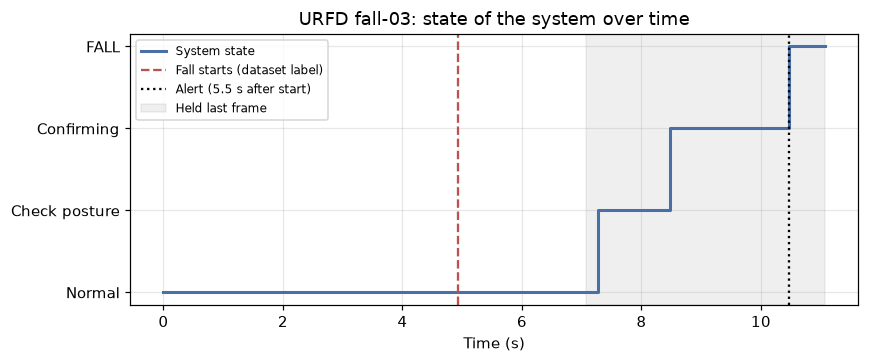

In [10]:
name = "fall-03"
alert, timeline = fx.replay_yolo(cache[name])
tl = pd.DataFrame(timeline)
state_level = {"NORMAL": 0, "LYING": 0.5, "POSSIBLE_FALL": 1, "CHECKING_DOWN": 2, "CONFIRMED_FALL": 3}
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.step(tl.time, tl.state.map(state_level), where="post", color="#4a6fa5", lw=2, label="System state")
ax.set_yticks([0, 1, 2, 3], ["Normal", "Check posture", "Confirming", "FALL"])
ax.axvline(onsets[name], color="#c0504d", ls="--", label="Fall starts (dataset label)")
if alert is not None:
    ax.axvline(alert, color="black", ls=":", label=f"Alert ({alert - onsets[name]:.1f} s after start)")
ax.axvspan(cache[name]["times"][-1], tl.time.iloc[-1], color="grey", alpha=.12, label="Held last frame")
ax.set_xlabel("Time (s)"); ax.set_title(f"URFD {name}: state of the system over time"); ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "fall_timeline.png", dpi=200); plt.show()

## 9. Logged metrics

In [11]:
main = comparison[(comparison.view == "held") & (comparison.clips == "test")].set_index("pipeline")
summary = {
    "dataset": "URFD camera 0, 15 fall + 15 ADL clips", "analysis_fps": 1 / fx.CADENCE, "hold_seconds": fx.HOLD,
    "test_held": main[["TP", "FN", "FP", "TN", "recall", "precision", "f1", "specificity", "accuracy"]].to_dict("index"),
    "median_alert_delay_s": delay.groupby("pipeline").delay_s.median().round(2).to_dict(),
    "median_ms_per_frame": dict(zip(speed.model, speed["median ms / frame"])),
}
(RESULTS / "fall_metrics.json").write_text(json.dumps(summary, indent=2))
summary

{'dataset': 'URFD camera 0, 15 fall + 15 ADL clips',
 'analysis_fps': 5.0,
 'hold_seconds': 4.0,
 'test_held': {'Previous (MediaPipe)': {'TP': 7,
   'FN': 6,
   'FP': 1,
   'TN': 12,
   'recall': 0.538,
   'precision': 0.875,
   'f1': 0.666,
   'specificity': 0.923,
   'accuracy': 0.731},
  'Current (YOLO11-pose)': {'TP': 9,
   'FN': 4,
   'FP': 0,
   'TN': 13,
   'recall': 0.692,
   'precision': 1.0,
   'f1': 0.818,
   'specificity': 1.0,
   'accuracy': 0.846}},
 'median_alert_delay_s': {'Current (YOLO11-pose)': 4.44,
  'Previous (MediaPipe)': 2.6},
 'median_ms_per_frame': {'YOLO11n-pose + ByteTrack (current)': 101.8,
  'MediaPipe Pose (previous)': 42.3}}

## Conclusion

- The current multi-person pipeline detects more falls than the previous one in the held view and raises no false alarms on the
  normal-activity clips.
- **Box continuation** is the most valuable addition: without it far fewer falls are detected (Experiment 3).
  **Track hand-off** also helps.
- The **stayed-down check** did not change any result on URFD; it only added delay (Experiment 2). URFD's normal
  clips contain no "drop and get straight back up" moments, which is exactly what the check is for, so its benefit
  cannot be measured on this dataset. It is kept as a safety margin for real rooms, and a shorter wait (e.g. 1 s)
  is a reasonable alternative.

**Limitations:** 30 short clips from one dataset and one camera angle, not separated by subject, with staged falls by
young actors. The figures are indicative. Larger and more varied data (other datasets, real rooms, older people) is
needed before any safety claim.